# Post 3: 2024 telework data checks

This notebook reruns the data-readiness checks and independent reconciliation. Run with the post directory as the working directory. Raw IPUMS files belong in `data/raw/`. Source: IPUMS CPS, University of Minnesota; underlying Census Bureau/BLS CPS data.

## Context & methods

Use all 12 Basic Monthly samples from 2024. Restrict to civilians ages 16+ at work in the reference week. Apply WTFINL weights once. The observations are person-months, not distinct people. Classify valid positive telework hours as some/all by comparison with actual hours at all jobs.

In [1]:
import sys, io, contextlib
from pathlib import Path
import pandas as pd
from IPython.display import display, SVG
sys.path.insert(0, str(Path('code').resolve()))
from check_data import run as check_data
from verify_data import run as verify_data
with contextlib.redirect_stdout(io.StringIO()):
    inventory = check_data()
    independent = verify_data()
assert independent['passed']
display(pd.DataFrame([{k: inventory[k] for k in ['year','monthly_samples','person_month_records','at_work_age_16_plus_records']}]))

,year,monthly_samples,person_month_records,at_work_age_16_plus_records
0,2024,12,1187356,545259


## Data

The DDI defines the fixed-width positions and implied decimals. ASECFLAG is structurally blank outside March; those blanks are not excluded. The table below lists all monthly sample sizes.

In [2]:
display(pd.read_csv('results/variables.csv')[['name','label','implied_decimals']])
display(pd.read_csv('results/sample_counts.csv'))

,name,label,implied_decimals
0,YEAR,Survey year,0
1,SERIAL,Household serial number,0
2,MONTH,Month,0
3,HWTFINL,"Household weight, Basic Monthly",4
4,CPSID,"CPSID, household record",0
5,ASECFLAG,Flag for ASEC,0
6,PERNUM,Person number in sample unit,0
7,WTFINL,Final Basic Weight,4
8,CPSIDP,"CPSID, person record",0
9,CPSIDV,Validated Longitudinal Identifier,0


,year,month,person_month_records
0,2024,1,99135
1,2024,2,99250
2,2024,3,95311
3,2024,4,99245
4,2024,5,99781
5,2024,6,98697
6,2024,7,99138
7,2024,8,100288
8,2024,9,99421
9,2024,10,99045


## Results

Figure 1 uses all people at work as its denominator. The within-teleworker split and intensity distribution use teleworkers with valid hours only. Two responses have positive telework status but zero telework hours; their hours category remains unknown.

In [3]:
annual = pd.read_csv('results/annual_summary.csv')
display(annual[['category','person_month_records','annual_average_people','share_of_people_at_work_pct','share_of_classifiable_teleworkers_pct']].round(3))
display(pd.DataFrame([independent]).drop(columns=['unclassifiable_hours']))

,category,person_month_records,annual_average_people,share_of_people_at_work_pct,share_of_classifiable_teleworkers_pct
0,No telework,422387,1.205262e+08,77.205,NaN
1,Some hours teleworked,64399,1.862201e+07,11.929,52.331
2,All hours teleworked,58471,1.696311e+07,10.866,47.669
3,Telework hours invalid or missing,2,4.197620e+02,0.000,NaN
4,Telework status unavailable,0,0.000000e+00,0.000,NaN


,passed,method,eligible_records,maximum_absolute_difference_annual_average_people,some_hours_share_pct,all_hours_share_pct,inference
0,True,Separate pandas fixed-width import and vectori...,545259,1.490116e-08,52.33089,47.66911,No confidence intervals or tests of monthly di...


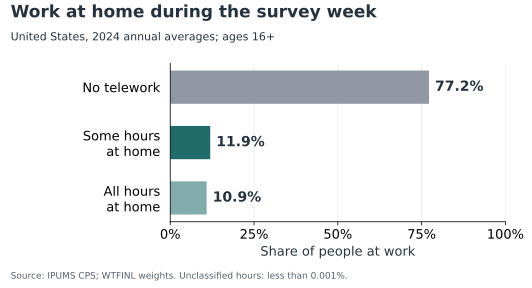

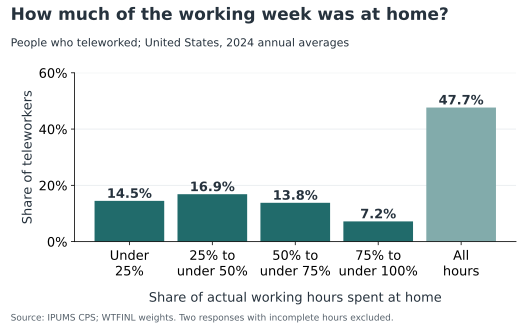

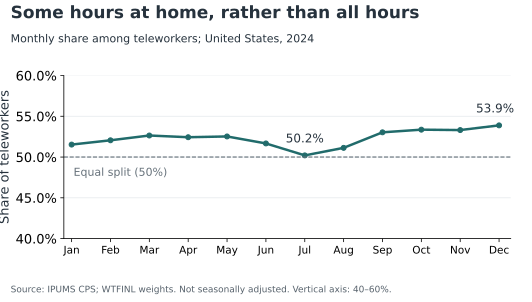

In [4]:
for figure in ['telework-status','telework-intensity','telework-monthly']:
    display(SVG(filename=f'results/{figure}.svg'))

## Takeaways

Interpret a survey-week arrangement, not an employment contract or preference. The non-telework hours cannot be assigned to an office or other specific location. Multiple jobs are combined. Monthly figures are unadjusted point estimates; no test of monthly differences is claimed. Documentation: [BLS telework concepts](https://www.bls.gov/cps/telework.htm).